# **CA1 - Data Visualisation and Communication**
## LUIS RAMIREZ - 2023169
video link: 

github link: https://github.com/LuisRamirezv/CA1--DataVisualisation

Datasets used:
Occupational Employment and Wage Statistics (OEWS) Tables

- 2023 -> provided by the lecturer
- 2025 -> https://www.bls.gov/oes/special-requests/oesm25all.zip

**Tech jobs in the US**

Employment statistics for the USA as of May 2023 in fields like AI, Data Science and Software Development.

## **Index**

1. [Libraries](#1.-LIBRARIES)
2. [Loading the data](#2.-LOADING-THE-DATA)
3. [Missing data](#3.-MISSING-DATA)
    - 3.1 Finding the symbols in the dataset
    - 3.2 Turn the symbols into NaN
4. [Choosing the tech occupations](#4.-CHOOSING-THE-TECH-OCCUPATIONS)
5. [Outliers](#5.-OUTLIERS)
6. [Visualisations](#6.-VISUALISATIONS)
    - 6.1 Employment by occupation (USA) - Bar chart
    - 6.2 Share of tech employment (USA) - Pie chart
    - 6.3 Salary by occupation (USA) - Box plot
    - 6.4 Salary by state (USA) - Heatmap
    - 6.5 Employment vs salary (USA) - Scatter plot
7. [Challenge: employment changes between 2023 and 2025](#7.-CHALLENGE:-Employment-changes-between-2023-and-2025)
    - 7.1 Employment change 2023 to 2025 (USA) - Bar chart
8. [Conclusion](#8.-CONCLUSION)
9. [References](#References)

### **1. LIBRARIES**

In [24]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **2. LOADING THE DATA**

The original file is an Excel file and is very slow to open (my firt try even had to be stopped). To fix that I convert it to a CSV one time and then I always read the CSV, which is much faster.
The cell below checks if the CSV already exists, so it safe to run mote than once. It only does the slow conversion the first time.

In [25]:
## Changing the format file to a CSV

FOLDER = r'C:\Users\felip\Documents\CA-DataVisual' # This is the folder where the files will be.
XLSX_PATH = os.path.join(FOLDER, "all_data_M_2023.xlsx")
CSV_PATH = os.path.join(FOLDER, "all_data_M_2023.csv")

# Only convert if the CSV is not there yet
if not os.path.exists(CSV_PATH):
    print("( (!) CSV not found, converting the Excel file (this can take a few minutes)...")
    pd.read_excel(XLSX_PATH).to_csv(CSV_PATH, index=False)
    print("Done!")
else:
    print("======> CSV already exists, nothing to convert <======")

======> CSV already exists, nothing to convert <======


Once I have the new CSV file, I can read it into df. I am going to use low_memory=False because pandas was giving me a DtypeWarning because some columns have numbers and symbols mixed, like * and #. With this option enabled, pandas reads the whole column before choosing the type, so the warnings go away.

In [26]:
df = pd.read_csv(CSV_PATH, low_memory=False)

print("Rows:", df.shape[0], "| columns:", df.shape[1]) # printing how meny columns and rows.
df.head() # Checking the dataset

Rows: 413327 | columns: 32


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## Running the new CSV file for this project

In [27]:
### Adding the new CSV DataFrame to df.
### With a new CSV file, the process will be faster.
csv_file = r"C:\Users\felip\Documents\CA-DataVisual\all_data_M_2023.csv"
df= pd.read_csv(csv_file)
df.head() #prove of the dataset working

C:\Users\felip\AppData\Local\Temp\ipykernel_33648\1920427162.py:4: DtypeWarning: Columns (4,13,14,15,16,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv(csv_file)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## Dealing with Missing Data ##

In [28]:
df.isnull().sum() # Checking how many missing values the dataset has.

AREA                 0
AREA_TITLE           0
AREA_TYPE            0
PRIM_STATE           0
NAICS                0
NAICS_TITLE          0
I_GROUP              0
OWN_CODE             0
OCC_CODE             0
OCC_TITLE            0
O_GROUP              0
TOT_EMP              0
EMP_PRSE             0
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN               0
A_MEAN               0
MEAN_PRSE            0
H_PCT10              0
H_PCT25              0
H_MEDIAN             0
H_PCT75              0
H_PCT90              0
A_PCT10              0
A_PCT25              0
A_MEDIAN             0
A_PCT75              0
A_PCT90              0
ANNUAL          396830
HOURLY          412572
dtype: int64

In [29]:
# Based on the information provided in the Excel file:
# '*'  = indicates that a wage estimate is not available
# '**'  = indicates that an employment estimate is not available
# '#'  = indicates a wage equal to or greater than $115.00 per hour or $239,200 per year
# '~' = indicates that the percent of establishments reporting the occupation is less than 0.5%

### STEP 1 ###
# Finding symbols to replace it
symbols = ['#', '*', '**', '~'] # Matching simbols.
df_str = df.astype(str).apply(lambda col: col.str.strip()) #  Turns every value in the table into text.
sym_table = pd.DataFrame({sym: (df_str == sym).sum() for sym in symbols}) # Compares every cell with one of the symbols
sym_table[(sym_table > 0).any(axis=1)] # Gives True if the symbols appear at least once.

,#,*,**,~
TOT_EMP,0,0,11598,0
EMP_PRSE,0,0,11598,0
JOBS_1000,0,0,3633,0
LOC_QUOTIENT,0,0,3633,0
PCT_TOTAL,0,0,7886,0
PCT_RPT,0,0,7886,52694
H_MEAN,269,20695,0,0
A_MEAN,269,5083,0,0
MEAN_PRSE,0,4431,0,0
H_PCT10,269,20695,0,0


In [30]:
### STEP 2 ###
# Converting symbols to NaN (so they count as missing from now on)
num_cols = ['TOT_EMP','H_MEAN','A_MEAN','H_PCT10','H_PCT25','H_MEDIAN','H_PCT75','H_PCT90',
            'A_PCT10','A_PCT25','A_MEDIAN','A_PCT75','A_PCT90']
for c in num_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '').str.strip(), errors='coerce')

df[num_cols].isnull().sum()


### Run STEP 1 and STEP 2 again after this, and the counts will no include the symbols values.

TOT_EMP     11598
H_MEAN      20964
A_MEAN       5352
H_PCT10     20964
H_PCT25     21426
H_MEDIAN    23059
H_PCT75     26119
H_PCT90     33008
A_PCT10      5353
A_PCT25      5815
A_MEDIAN     7474
A_PCT75     10606
A_PCT90     17844
dtype: int64

### **3. MISSING DATA**

First, I have to count the missing values in every column

In [31]:
missing = df.isnull().sum()
missing[missing >0] # Only show the columns that have missing values

TOT_EMP          11598
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN           20964
A_MEAN            5352
H_PCT10          20964
H_PCT25          21426
H_MEDIAN         23059
H_PCT75          26119
H_PCT90          33008
A_PCT10           5353
A_PCT25           5815
A_MEDIAN          7474
A_PCT75          10606
A_PCT90          17844
ANNUAL          396830
HOURLY          412572
dtype: int64

Some columns too many missing values ( for example PCT_TOTAL and PCT_RPT), but this count is not the full story. The Excel file says that the data uses spacial symbols instead of numbers in some cells:
| Symbol | Meaning |
|---|---|
| `*` | wage estimate not available |
| `**` | employment estimate not available |
| `#` | wage is $115.00/hour or $239,200/year **or more** |
| `~` | less than 0.5% of establishments report this occupation |

So some columns have symbols hidden in them that pandas does not count as missing. 

###         *3.1 Finding the symbols in the dataset*

In [32]:
symbols = ['#', '*', '**', '~']

# Turn everything into tex, and remove spaces, so I can compare with the symbols.
df_str = df.astype(str).apply(lambda col: col.str.strip())

# for each symbol, count how many time it shows up in each column
sym_table = pd.DataFrame({sym: (df_str ==sym).sum() for sym in symbols})

# show only the columns where at least one symbol appear
sym_table[(sym_table >0).any(axis=1)]

,#,*,**,~
EMP_PRSE,0,0,11598,0
JOBS_1000,0,0,3633,0
LOC_QUOTIENT,0,0,3633,0
PCT_TOTAL,0,0,7886,0
PCT_RPT,0,0,7886,52694
MEAN_PRSE,0,4431,0,0


the symbols appear in TOT_EMP, EMP_PRSE, JOBS_1000, LOC_QUOTIENT, PCT_TOTAL, PCT_RPT, H_MEAN, A_MEAN, MEAN_PRSE, H_PCT10, H_PCT25, H_MEDIAN, H_PCT75, H_PCT90, A_PCT10, A_PCT25, A_MEDIAN, A_PCT75, and A_PCT90.
Next, I need to fix the numeric columns that I am going to use (employment and wages)

###         *3.2 Turn the symbols into NaN*

The wage and employment columns have symbols in them, so pandas reads them as text. Whith the function pd.to_ numeric(..., errors='coerce') every value that is not a real number becomes NaN, and I will remove commmas first, for example '1,234,567'.

In [33]:
num_cols = ['TOT_EMP', 'H_MEAN', 'A_MEAN', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90',
            'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

for c in num_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',','').str.strip(),errors='coerce')

# Missing values now include the symbols
df[num_cols].isnull().sum()

TOT_EMP     11598
H_MEAN      20964
A_MEAN       5352
H_PCT10     20964
H_PCT25     21426
H_MEDIAN    23059
H_PCT75     26119
H_PCT90     33008
A_PCT10      5353
A_PCT25      5815
A_MEDIAN     7474
A_PCT75     10606
A_PCT90     17844
dtype: int64

In [34]:
df.head() # With this function, I can quickly check the results.

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.40,29050.0,35660.0,48060.0,76980.0,121470.0,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550.0,78330.0,116880.0,169090.0,231620.0,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,NaN,46400.0,66170.0,103460.0,165500.0,NaN,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,NaN,NaN,80000.0,130840.0,206680.0,NaN,NaN,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,NaN,NaN,80000.0,130840.0,206680.0,NaN,NaN,NaN,NaN


Now the counts include the symbols too, so they are the real numbers of missing values. I don't delete rows with missing values from the whole dataset, as that would remove too much data; instead, I drop NaN values only in the specific column I use for each chart.

### **4. CHOOSING THE TECH OCCUPATIONS**

The dataset has hundred of occupations, so I keep only the tech ones using their SOC 2019 codes*, and I also make three smaller tables:

- `us` : national totals (`AREA_TYPE = 1`)
- `states` : state rows (`AREA_TYPE = 2`)
- `metro` : metro area rows (`AREA_TYPE = 4`)

I only use the Cross-industry rows so I don't count the same workers twice.

\**The 6-digit Standard Occupational Classification (SOC) code or OEWS-specific code for the occupation*

In [35]:
tech_codes = {
    '15-1221': 'Computer & Info Research Scientists',
    '15-2051': 'Data Scientists',
    '15-1252': 'Software Developers',
    '15-1251': 'Computer Programmers',
    '15-1253': 'Software QA Analysts & Testers',
    '15-1211': 'Computer Systems Analysts',
    '15-1212': 'Information Security Analysts',
    '15-1242': 'Database Administrators',
    '15-1243': 'Database Architects',
    '15-1255': 'Web & Digital Interface Designers',
    '15-2031': 'Operations Research Analysts',
    '15-2041': 'Statisticians',
}
df['OCC_CODE'] = df['OCC_CODE'].astype(str).str.strip()
tech = df[
    df['OCC_CODE'].isin(tech_codes)
    & (df['NAICS_TITLE'] == 'Cross-industry')   # avoid double counting industries
].copy()
tech['OCC_SHORT'] = tech['OCC_CODE'].map(tech_codes)

us     = tech[tech['AREA_TYPE'] == 1].copy()
states = tech[tech['AREA_TYPE'] == 2].copy()
metro  = tech[tech['AREA_TYPE'] == 4].copy()

us[['OCC_SHORT','TOT_EMP','A_MEDIAN']]

,OCC_SHORT,TOT_EMP,A_MEDIAN
135,Computer Systems Analysts,498810.0,103800.0
136,Information Security Analysts,175350.0,120360.0
138,Computer & Info Research Scientists,35210.0,145080.0
144,Database Administrators,76140.0,101510.0
145,Database Architects,59920.0,134700.0
148,Computer Programmers,120370.0,99700.0
149,Software Developers,1656880.0,132270.0
150,Software QA Analysts & Testers,203040.0,101800.0
152,Web & Digital Interface Designers,111060.0,98540.0
161,Operations Research Analysts,117880.0,83640.0


I get 12 national rows, one per occupation.

### **5. OUTLIERS**

I use the **IQR rule** per occupation: a value is an outlier if it is:

- below `Q1 - 1.5*IQR` or
- above `Q3 + 1.5*IQR`.
  
I apply it to the annual median salary (`A_MEDIAN`) across metro areas, because that is where extreme values are most likely (e.g. San Francisco or San Jose vs. small cities).

Note: the `#` symbol (wage >= $239,200) was converted to NaN earlier. Those are *top-coded*, not missing at random, so I drop NaNs only for the specific column I am plotting and I keep in mind that the highest salaries are slightly under-represented.

In [36]:
def flag_outliers(group, col='A_MEDIAN'):
    q1, q3 = group[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    group = group.copy()
    group['IS_OUTLIER'] = (group[col] < low) | (group[col] > high)
    return group

metro_valid = metro.dropna(subset=['A_MEDIAN', 'TOT_EMP'])
metro_flagged = (metro_valid.groupby('OCC_SHORT', group_keys=False)
                            .apply(flag_outliers))

print(metro_flagged.groupby('OCC_SHORT')['IS_OUTLIER'].agg(['sum', 'count']))

# Cleaned version with no outliers used only where extreme values would hide the main pattern
metro_clean = metro_flagged[~metro_flagged['IS_OUTLIER']]
print("Rows before:", len(metro_flagged), "| after removing outliers:", len(metro_clean))

                                     sum  count
OCC_SHORT                                      
Computer & Info Research Scientists    5     64
Computer Programmers                   9    230
Computer Systems Analysts              5    360
Data Scientists                        3    242
Database Administrators                3    197
Database Architects                    7    128
Information Security Analysts         17    225
Operations Research Analysts           2    184
Software Developers                    9    378
Software QA Analysts & Testers         7    213
Statisticians                          1     90
Web & Digital Interface Designers     12    172
Rows before: 2483 | after removing outliers: 2403


C:\Users\felip\AppData\Local\Temp\ipykernel_33648\360564786.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(flag_outliers))


### **6. VISUALISATIONS**

##### **6.1 Employment by occupation (USA) - BAR CHART**

**Objective:** In this first visualisation, I am going to compare which tech occupation employs the most people.

**Why this visualisation:** With one categorical variable (occupation) against one numeric variable (employment), a horizontal bar chart is the clearest way to compare sizes, and long occupation names stay readable.

**What I learned about AI employment from this:** Software developers are by far the largest tech occupation in the US in 2023, but in 2023, AI was still a smaller part of the workforce industry. With a bout 1.6 million workers, it is more than three times the second one (Computer Systems Analyst). On the other hand, the more "advanced" jobs are really small, for example, computer and research scientists with only about 35.000.

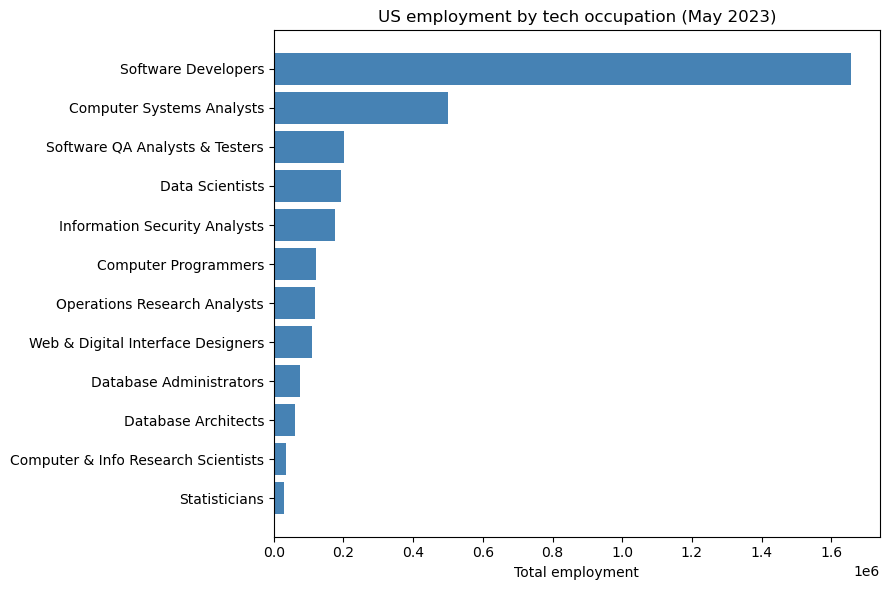

In [37]:
d = us.sort_values('TOT_EMP')
plt.figure(figsize=(9, 6))
plt.barh(d['OCC_SHORT'], d['TOT_EMP'], color='steelblue')
plt.xlabel('Total employment')
plt.title('US employment by tech occupation (May 2023)')
plt.tight_layout()
plt.show()

##### **6.2  Share of tech employment (USA) - PIE CHART**

**Objective:** In this visualisation, I am going to represent each job's share percentage of the tech industry in the USA.

**Why this visualisation:** The pie chart is the most optimal graphic representation of the total share per job or occupation in an industry. A pie chart is only readable with a few slices, so I am going to group every occupation with less than 5% into one slice called Other. 

**What I learned about AI employment from this:** Software developers alone are about half (50,6%) of all tech jobs. This representation represents how important the Software Development role is for the tech industry. The job most related to AI in 2023 was Data Scientists, and it is only 5,9% of the total industry.

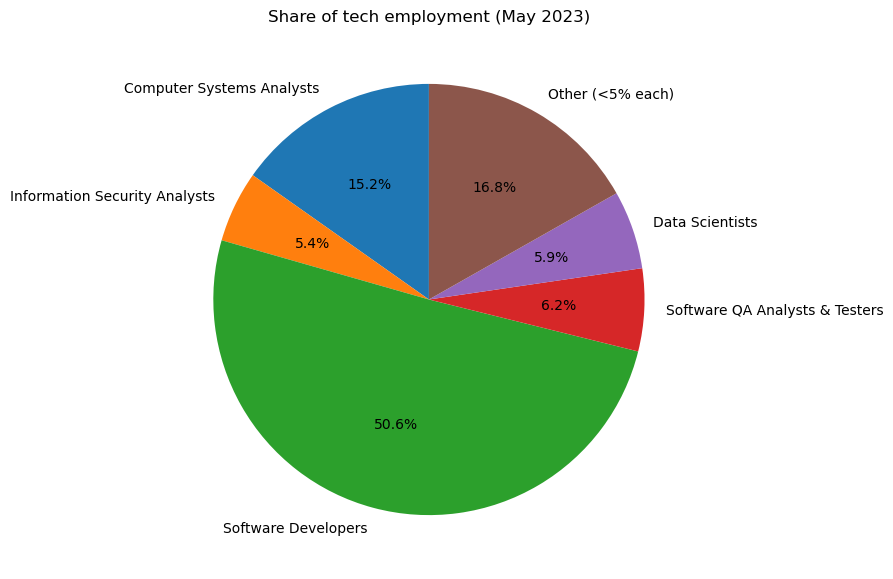

In [38]:
share = us.set_index('OCC_SHORT')['TOT_EMP']
pct = share / share.sum()
small = pct[pct < 0.05].sum()
pie_data = share[pct >= 0.05].copy()
pie_data['Other (<5% each)'] = share[pct < 0.05].sum()

plt.figure(figsize=(7, 7))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of tech employment (May 2023)')
plt.show()

##### **6.3  Salary by occupation (USA) - BOX PLOT**

**Objective:** In this visualisation, I am going to do a distribution and comparison of how much the different tech occupations pay, and how much the pay changes between metro areas. 

**Why this visualisation:** The box plot shows the median, the spread and the outliers of each occupation in one picture, so I can compare the 12 occupations side by side. The dots are the outliers that I found with the IQR rule, which is why I use metro_flagged. 

**What I learned about AI employment from this:** The occupations closer to research and software engineering are at the top of the chart, and the roles closer to support or design are lower. Data Scientist (AI work-related) are in the upper part, so a data science job pays well compared with most tech jobs.

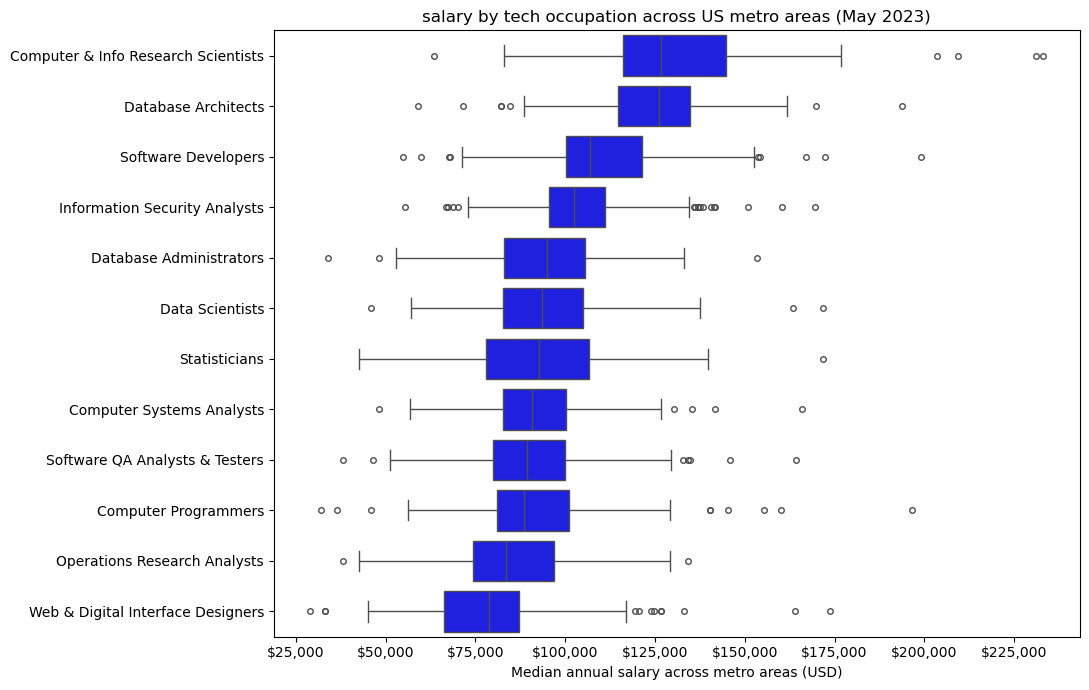

In [39]:
# Order the occupations from the highest to the lowest media salary
order = (metro_flagged.groupby('OCC_SHORT')['A_MEDIAN']
                      .median()
                      .sort_values(ascending=False)
                      .index)

fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=metro_flagged, y='OCC_SHORT', x='A_MEDIAN', order=order,
            color='blue', fliersize=4, ax=ax)

ax.set_xlabel('Median annual salary across metro areas (USD)')
ax.set_ylabel('')

ax.set_title('salary by tech occupation across US metro areas (May 2023)')
ax.xaxis.set_major_formatter(lambda x, pos: f"${x:,.0f}")
plt.tight_layout()
plt.show()

##### **6.4  Salary by state (USA) - HEAT MAP**

**Objective:** In this visualisation, I am going to compare and investigate which states pay the most, and how the pay of AI-related jobs compares with software jobs in the same state.

**Why this visualisation:** A heatmap works well when I have two categories (state and occupation) and one number (median salary). The colour shows the high and low salaries quickly, and the number inside each cell gives the exact value (in thousands of dollars). I show only the top 10 states for Software Developers because there are more than 50 states, and the map would be too big to read.

**What I learned about AI employment from this:** California and Washington pay the most for Software Developers and for Data Scientists.In most states, software developers earn more than Data Scientists. In more states, software developers earn more than data scientists, but there are exceptions: In Virginia, data scientists earn slightly more than software developers. Computer and Info Research Scientists are among the best paid in the states where they have a value.

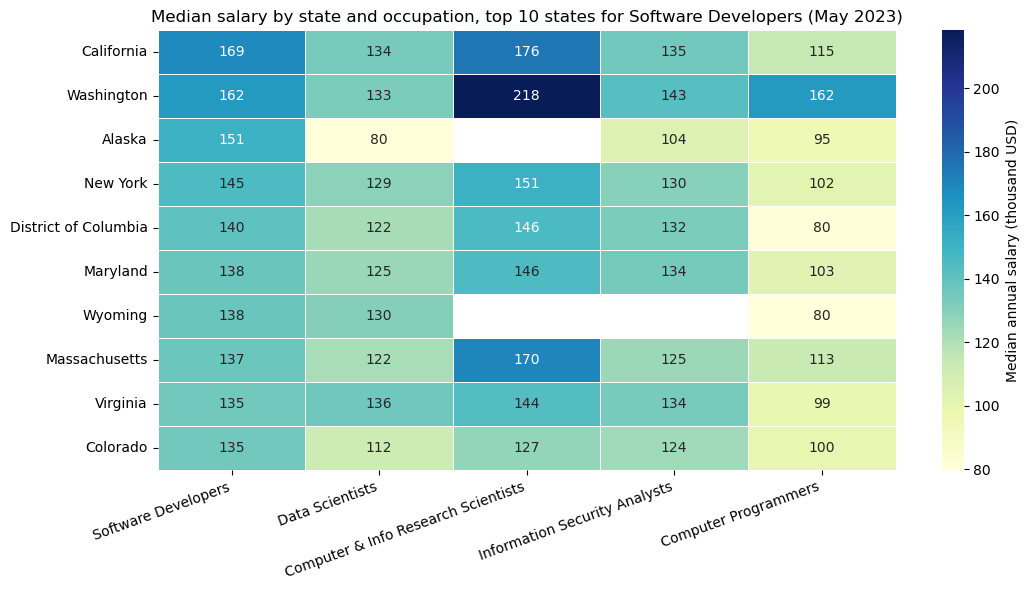

In [40]:
two_occupation = ['Software Developers', 'Data Scientists']      # I still need this list for 6.5

# Occupations I want to compare in the heatmap
heat_occ = ['Software Developers', 'Data Scientists', 'Computer & Info Research Scientists',
            'Information Security Analysts', 'Computer Programmers']

# Table: one row per state, one column per occupation, values = median annual salary
state_pay = (states[states['OCC_SHORT'].isin(heat_occ)]
             .pivot_table(index='AREA_TITLE', columns='OCC_SHORT', values='A_MEDIAN'))

# Top 10 states by Software Developer salary (highest salary on top)
top10_states = (state_pay.dropna(subset=['Software Developers'])
                         .nlargest(10, 'Software Developers'))[heat_occ]

plt.figure(figsize=(11, 6))
sns.heatmap(top10_states / 1000, # salaries in thousands of dollars to keep the numbers short
            annot=True, fmt='.0f',# show the number inside each cell
            cmap='YlGnBu', linewidths=0.5,
            cbar_kws={'label': 'Median annual salary (thousand USD)'})


plt.xlabel('')
plt.ylabel('')
plt.title('Median salary by state and occupation, top 10 states for Software Developers (May 2023)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

##### **6.5  Employment vs salary (USA) - SCATTER PLOT**

**Objective:** I am going to probe whether the metro areas that have more tech workers also pay more.

**Why this visualisation:** For this chart, I have two numeric variables (employment and median salary), and the scatter plot is the standard chart to look for a relationship between two numbers. Each dot is one metro area, and I used a log scale for employment because a few giant cities (like NY) would squash all the other dots on the left.

**What I learned about AI employment from this:** There is a positive relationship in general. The metro areas with more tech workers also pay more, which is what I would expect because big tech hubs have more demand and a higher cost of living. But the relationship is not perfect. There are small areas with high salaries and big areas with average salaries.

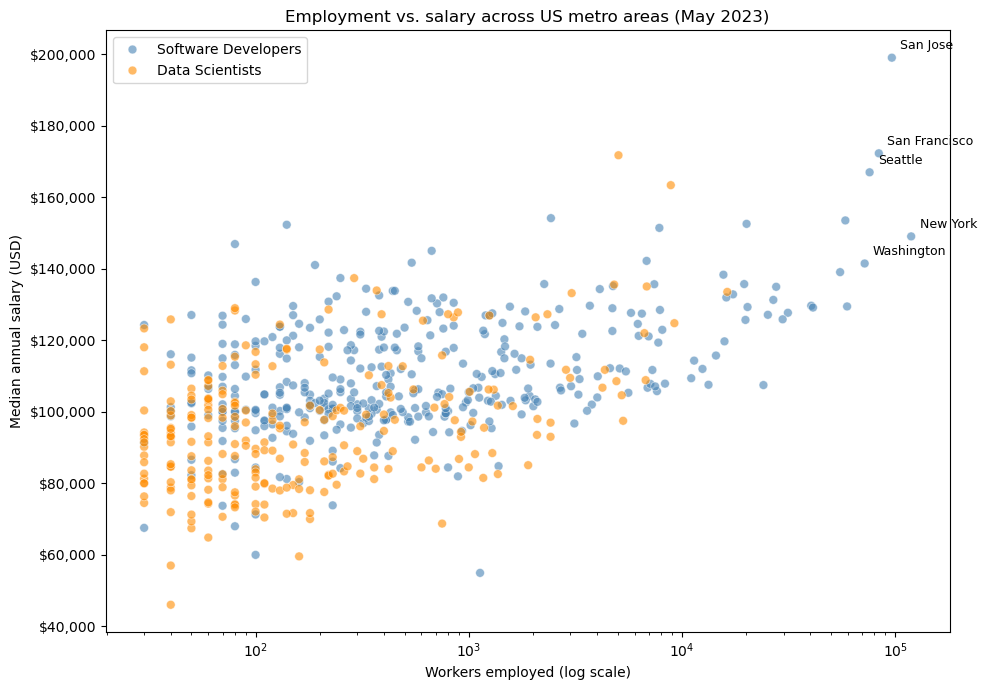

In [41]:
sc = metro_flagged[metro_flagged['OCC_SHORT'].isin(two_occupation)]

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=sc, x='TOT_EMP', y='A_MEDIAN', hue='OCC_SHORT',
                hue_order=two_occupation, palette=['steelblue', 'darkorange'],
                alpha=0.6, s=40, ax=ax)

# Name the 5 metro areas with the most Software Developers
big5 = sc[sc['OCC_SHORT'] == 'Software Developers'].nlargest(5, 'TOT_EMP')
for _, r in big5.iterrows():
    ax.annotate(r['AREA_TITLE'].split('-')[0].split(',')[0],
                (r['TOT_EMP'], r['A_MEDIAN']),
                textcoords='offset points', xytext=(6, 6), fontsize=9)


    ax.set_xscale('log')
ax.set_xlabel('Workers employed (log scale)')
ax.set_ylabel('Median annual salary (USD)')
ax.set_title('Employment vs. salary across US metro areas (May 2023)')
ax.yaxis.set_major_formatter(lambda y, pos: f"${y:,.0f}")
ax.legend(title='')
plt.tight_layout()
plt.show()

### **7. CHALLENGE:  Employment changes between 2023 and 2025**

So far, I have only used one year (2023). To see how AI-related employment changes over time, I used an extra dataset from the same website (https://www.bls.gov/oes/tables.htm). So, to acomplish this challenge, I downloaded the same dataset but from 2025.

As I did before, csv files are faster to run and work it, so I am goin to reuse the same code to create a csv file from the original dataset.

In [42]:
## STEP 1: Changing the format file to a CSV

FOLDER = r'C:\Users\felip\Documents\CA-DataVisual' # This is the folder where the files will be.
XLSX_PATH = os.path.join(FOLDER, "all_data_M_2025.xlsx")
CSV_PATH25 = os.path.join(FOLDER, "all_data_M_2025.csv")

# Only convert if the CSV is not there yet
if not os.path.exists(CSV_PATH25):
    print("( (!) CSV not found, converting the Excel file (this can take a few minutes)...")
    pd.read_excel(XLSX_PATH).to_csv(CSV_PATH25, index=False)
    print("Done!")
else:
    print("======> CSV already exists, nothing to convert <======")

======> CSV already exists, nothing to convert <======


In [43]:
# Loading and cleaning the 2025 CSV

df25 = pd.read_csv(CSV_PATH25, low_memory=False) #low_memory = FALSE to avoid the DtypeWarning

print("Rows:", df25.shape[0], "| columns:", df25.shape[1]) # Quick check that the file loaded well 
df25.head()

# Occupations I use (same list as before)
tech_codes = {
    '15-1221': 'Computer & Info Research Scientists',
    '15-2051': 'Data Scientists',
    '15-1252': 'Software Developers',
    '15-1251': 'Computer Programmers',
    '15-1253': 'Software QA Analysts & Testers',
    '15-1211': 'Computer Systems Analysts',
    '15-1212': 'Information Security Analysts',
    '15-1242': 'Database Administrators',
    '15-1243': 'Database Architects',
    '15-1255': 'Web & Digital Interface Designers',
    '15-2031': 'Operations Research Analysts',
    '15-2041': 'Statisticians',
}

Rows: 413527 | columns: 32


In [44]:
# 2023 table: national, cross-industry rows taken directly from df (dataset 2023)
df['OCC_CODE'] = df['OCC_CODE'].astype(str).str.strip() # remove spaces 
nat23 = df[(df['AREA_TYPE'] == 1)
           & (df['NAICS_TITLE'] == 'Cross-industry') # cross-industry so I don't count workers twice
           & (df['OCC_CODE'].isin(tech_codes))].drop_duplicates(subset='OCC_CODE').copy()
nat23['OCC_SHORT'] = nat23['OCC_CODE'].map(tech_codes)


In [45]:
# Cleaning the dataset and changing to NaN
# Symbols (#, *, **) -> NaN (same cleaning as the dataset of 2023)
for c in ['TOT_EMP', 'A_MEDIAN']:
    df25[c] = pd.to_numeric(df25[c].astype(str).str.replace(',', '').str.strip(), errors='coerce')

# Same filter for the 2025 table
df25['OCC_CODE'] = df25['OCC_CODE'].astype(str).str.strip()
nat25 = df25[(df25['AREA_TYPE'] == 1)
             & (df25['NAICS_TITLE'] == 'Cross-industry')
             & (df25['OCC_CODE'].isin(tech_codes))].drop_duplicates(subset='OCC_CODE').copy()
nat25['OCC_SHORT'] = nat25['OCC_CODE'].map(tech_codes)


In [46]:
# One table with both years: I join them using the occupation name as the index
cmp = (nat23.set_index('OCC_SHORT')[['TOT_EMP', 'A_MEDIAN']].add_suffix('_2023') # Adding the "_2023" to the column names
         .join(nat25.set_index('OCC_SHORT')[['TOT_EMP', 'A_MEDIAN']].add_suffix('_2025'), how='inner'))

# How many job were added or lost, and the % change compared with 2023
cmp['EMP_CHANGE'] = cmp['TOT_EMP_2025'] - cmp['TOT_EMP_2023']
cmp['EMP_CHANGE_PCT'] = cmp['EMP_CHANGE'] / cmp['TOT_EMP_2023'] * 100

cmp.sort_values('EMP_CHANGE_PCT', ascending=False).round(1)# Biggest growth first

# Showing table with both years.

,TOT_EMP_2023,A_MEDIAN_2023,TOT_EMP_2025,A_MEDIAN_2025,EMP_CHANGE,EMP_CHANGE_PCT
OCC_SHORT,,,,,,
Data Scientists,192710.0,108020.0,262440.0,120230.0,69730.0,36.2
Database Architects,59920.0,134700.0,67140.0,139500.0,7220.0,12.0
Information Security Analysts,175350.0,120360.0,190650.0,129180.0,15300.0,8.7
Computer & Info Research Scientists,35210.0,145080.0,37200.0,140300.0,1990.0,5.7
Computer Systems Analysts,498810.0,103800.0,519530.0,105850.0,20720.0,4.2
Web & Digital Interface Designers,111060.0,98540.0,113330.0,104000.0,2270.0,2.0
Software Developers,1656880.0,132270.0,1687890.0,135980.0,31010.0,1.9
Statisticians,29950.0,104110.0,29030.0,105650.0,-920.0,-3.1
Operations Research Analysts,117880.0,83640.0,108510.0,88940.0,-9370.0,-7.9


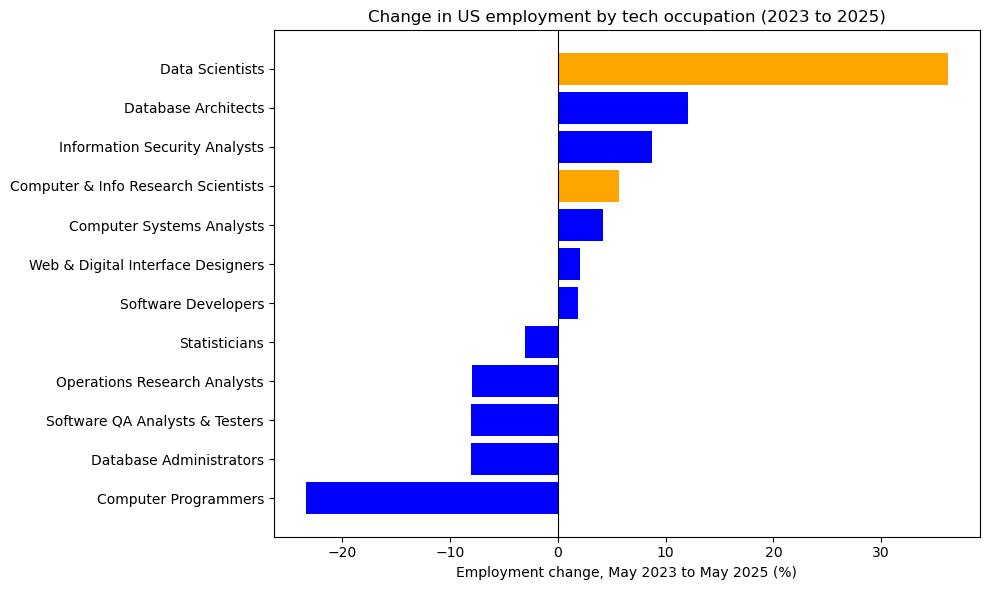

In [47]:
# The two jobs I use as AI proxies will be orange in the chart
ai_proxy = ['Data Scientists', 'Computer & Info Research Scientists']

# Sorted so the chart is easy to read
d = cmp.dropna(subset=['EMP_CHANGE_PCT']).sort_values('EMP_CHANGE_PCT') 
colors = ['orange' if occ in ai_proxy else 'blue' for occ in d.index]

plt.figure(figsize=(10, 6))
plt.barh(d.index, d['EMP_CHANGE_PCT'], color=colors)
plt.axvline(0, color='black', linewidth=0.8) # line at 0: bars on the right grew, on the left shrank
plt.xlabel('Employment change, May 2023 to May 2025 (%)')
plt.title('Change in US employment by tech occupation (2023 to 2025)')
plt.tight_layout()
plt.show()


**Objective:** In this visualisation, I compare how employment in each tech occupation changed between May 2023 and May 2025, and I check what happened to AI-related jobs like Data Scientists and Computer & Info Research Scientists (in orange).

**Why this visualisation:** I am comparing one number across a category (occupation), so a horizontal bar chart is the clearest option. The bars going right or left of the zero line show growth or decline immediately. I use the % change and not the raw numbers because software developers have about 1.6 million workers and data scientists only about 200,000.

**What I learned about AI employment from this:** AI-related employment is growing much faster than general software employment. Data Scientists grew by 36% (aprox), the biggest growth of all the occupations, while Software Developers only grew by 1%. The other AI proxy, Computer & Information Research Scientist, grew 5%, just a small change, but is a very small occupation.
At the other end, the more traditional roles lost jobs: Computer programmers fell by 20% (aprox) and Software QA Analyst, Database Administrator, and Operations Research Analyst decreased by around 8%.

### **8. CONCLUSION**

In May 2023, Software Developers were by far the biggest tech occupation in the US, with about 1.66 million workers (50% of the tech jobs). The jobs closest to AI were much smaller, about 5.9% for Data Scientists and (<5%) for Computer and Information Research Scientists. One positive aspect is the good pay for Research Scientists with a median salary of $145,000, followed by Software Developers $132,270 and Data Scientists with $108,020. But the pay depends on the location, for example, California and Washington paid Sofwtare DEvelopers the most, and metro areas with more tech workers generally paid more. 

The Challenge shows how fast the market is changing. between 2023 and 2025, Data Scientist grew by 35%, compared with only 2% for Software Developers, while Computer Programmers fell by 23%. So AI-related work is still a samll part of tech employment, but it is growing much faster than the rest.

This CA was challenging, especially the data preparation. The excel file was so slow that my firts attepmt had to be stopped, so I learned to conver it to CSV once and reuse it. I also found that the missing values were hidden behind symbols like "#" and "*", so a simple 'isnull()' was not enough. Choosing the right chart for each question and explaining why was also harder that I expected.

In the end, I learned how to clean a large real dataset with pandas, how to detect outliers with the IQR that I been learning in classes with Mohammed, and how to build different charts with matplotlib and seaborn.
